# Stage 1 (improved): fire / smoke image classifier
Four classes: `none`, `smoke`, `fire`, `both`.

1. Load the same `Dataset_fire` data as the baseline
2. Re-evaluate the saved baseline CNN (from `Fire_Stage1_CNN.ipynb`) on the test set
3. Train an improved model: MobileNetV2 (pretrained) with augmentation, dropout and early stopping
4. Compare the two, look at the mistakes, predict on single images

Run the cells one at a time, top to bottom.

## 1. Setup

In [14]:
import os
os.makedirs('models', exist_ok=True)
print('Working folder:', os.getcwd())
print('Contains:', os.listdir('.'))
for s in ['train', 'validation', 'test']:
    assert os.path.isdir(f'Dataset_fire/{s}'), f'Missing Dataset_fire/{s}. Run build_fire_dataset.py first.'
print('Dataset_fire found.')

Working folder: d:\Y3 S1\Project Practicum\DFire_detection
Contains: ['build_fire_dataset.py', 'Dataset_fire', 'DFire', 'Fire_Stage1_CNN.ipynb', 'Fire_Stage1_Improved.ipynb', 'history_fire.csv', 'history_fire_mobilenet_stageA.csv', 'history_fire_mobilenet_stageB.csv', 'models']
Dataset_fire found.


In [15]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
tf.random.set_seed(SEED); np.random.seed(SEED)
print('TensorFlow', tf.__version__)

TensorFlow 2.22.0-rc0


## 2. Data

In [16]:
CLASSES  = ['none', 'smoke', 'fire', 'both']   # same order as the baseline notebook
IMG_SIZE = (224, 224)                          # MobileNetV2's native size (baseline used 200x200)
BATCH    = 32

# Augmentation on training images only. Brightness changes help with day/night scenes.
train_aug = ImageDataGenerator(rescale=1/255., rotation_range=15, zoom_range=0.2,
                               width_shift_range=0.1, height_shift_range=0.1,
                               horizontal_flip=True, brightness_range=(0.7, 1.3))
plain = ImageDataGenerator(rescale=1/255.)

def make_gen(gen, split, size, shuffle, batch=BATCH):
    return gen.flow_from_directory(f'Dataset_fire/{split}', target_size=size, classes=CLASSES,
                                   batch_size=batch, class_mode='categorical',
                                   shuffle=shuffle, seed=SEED)

train_gen = make_gen(train_aug, 'train', IMG_SIZE, True)
val_gen   = make_gen(plain, 'validation', IMG_SIZE, False)
test_gen  = make_gen(plain, 'test', IMG_SIZE, False)   # shuffle=False so labels match predictions
print(train_gen.class_indices)

Found 5393 images belonging to 4 classes.
Found 951 images belonging to 4 classes.
Found 1420 images belonging to 4 classes.
{'none': 0, 'smoke': 1, 'fire': 2, 'both': 3}


In [17]:
w = compute_class_weight('balanced', classes=np.arange(len(CLASSES)), y=train_gen.classes)
class_weight = dict(enumerate(w))
print({CLASSES[k]: round(v, 2) for k, v in class_weight.items()})

{'none': np.float64(0.88), 'smoke': np.float64(0.88), 'fire': np.float64(1.68), 'both': np.float64(0.88)}


## 3. Helper functions

In [18]:
results = {}
predictions = {}

def fit_model(model, name, epochs):
    callbacks = [
        EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
        ModelCheckpoint(f'models/{name}.keras', monitor='val_loss', save_best_only=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1),
    ]
    hist = model.fit(train_gen, validation_data=val_gen, epochs=epochs,
                     class_weight=class_weight, callbacks=callbacks)
    pd.DataFrame(hist.history).to_csv(f'history_{name}.csv', index=False)
    return hist

def plot_history(hist, title):
    h = hist.history
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h['accuracy'], label='train'); ax[0].plot(h['val_accuracy'], label='validation')
    ax[0].set_title(f'{title}: accuracy'); ax[0].set_xlabel('epoch'); ax[0].legend()
    ax[1].plot(h['loss'], label='train'); ax[1].plot(h['val_loss'], label='validation')
    ax[1].set_title(f'{title}: loss'); ax[1].set_xlabel('epoch'); ax[1].legend()
    plt.tight_layout(); plt.show()

def evaluate(model, name, gen):
    probs = model.predict(gen, verbose=0)
    y_pred = np.argmax(probs, axis=1)
    y_true = gen.classes
    acc = (y_pred == y_true).mean()
    results[name] = acc
    predictions[name] = y_pred
    print(f'{name}: real test accuracy = {acc * 100:.2f}%\n')
    print(classification_report(y_true, y_pred, target_names=CLASSES, zero_division=0))
    plt.figure(figsize=(6.5, 5.5))
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASSES, yticklabels=CLASSES)
    plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(f'Confusion matrix: {name}')
    plt.tight_layout(); plt.show()

## 4. Baseline (your teacher's CNN, saved earlier)
Loads `models/fire_cnn_stage1.h5` and measures it on the same test images, so both models are compared fairly.
The baseline used 200x200 images, so it gets its own test generator.

Found 1420 images belonging to 4 classes.
Baseline CNN: real test accuracy = 70.14%

              precision    recall  f1-score   support

        none       0.78      0.72      0.75       400
       smoke       0.84      0.59      0.70       400
        fire       0.60      0.75      0.67       220
        both       0.62      0.77      0.68       400

    accuracy                           0.70      1420
   macro avg       0.71      0.71      0.70      1420
weighted avg       0.72      0.70      0.70      1420



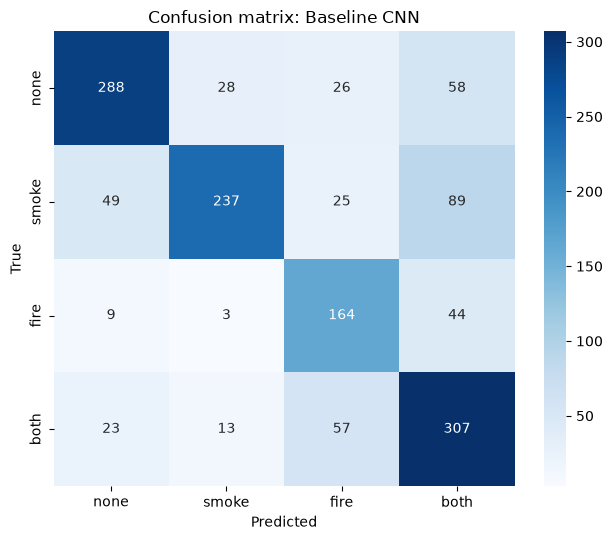

In [19]:
baseline_path = 'models/fire_cnn_stage1.h5'
if os.path.exists(baseline_path):
    baseline = tf.keras.models.load_model(baseline_path, compile=False)
    test_gen_200 = make_gen(plain, 'test', (200, 200), False, batch=10)
    evaluate(baseline, 'Baseline CNN', test_gen_200)
else:
    print(f'{baseline_path} not found. Skipping the baseline. '
          'You can still enter your earlier result by hand: results["Baseline CNN"] = 0.7014')

## 5. Improved model: MobileNetV2 (transfer learning)
Stage A trains only the new top layers. Stage B fine-tunes the last layers with a small learning rate.
Early stopping ends training once validation loss stops improving, so the epoch counts below are maximums.

Epoch 1/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 148s 861ms/step - accuracy: 0.5719 - loss: 0.9342 - val_accuracy: 0.6698 - val_loss: 0.7754 - learning_rate: 0.0010
Epoch 2/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 82s 485ms/step - accuracy: 0.6631 - loss: 0.7777 - val_accuracy: 0.7140 - val_loss: 0.7116 - learning_rate: 0.0010
Epoch 3/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 81s 481ms/step - accuracy: 0.6902 - loss: 0.7215 - val_accuracy: 0.7077 - val_loss: 0.6990 - learning_rate: 0.0010
Epoch 4/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 160s 949ms/step - accuracy: 0.7005 - loss: 0.7028 - val_accuracy: 0.7329 - val_loss: 0.6746 - learning_rate: 0.0010
Epoch 5/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 136s 552ms/step - accuracy: 0.7109 - loss: 0.6740 - val_accuracy: 0.6993 - val_loss: 0.6782 - learning_rate: 0.0010
Epoch 6/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 81s 477ms/step - accuracy: 0.7304 - loss: 0.6448 - val_accuracy: 0.7340 - val_loss: 0.6409 - learning_rate: 5.0000e-04
Epoch 7/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 120s 711ms/step - accuracy: 0.

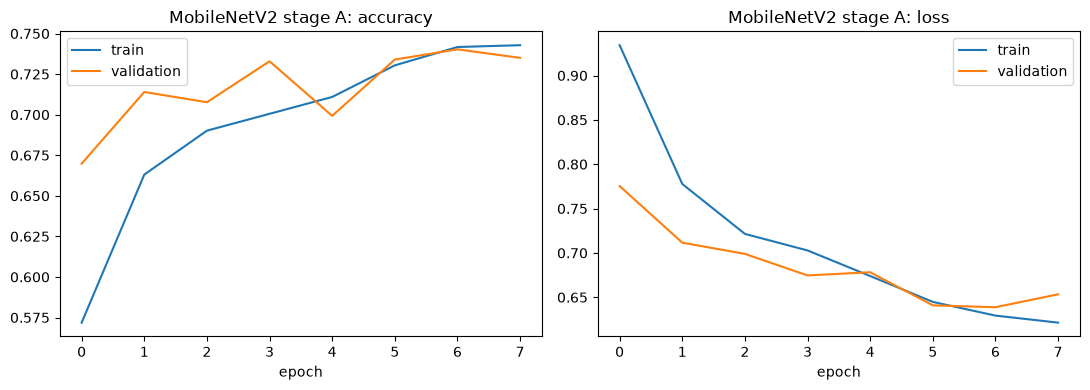

In [7]:
def build_mobilenet():
    base = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights='imagenet')
    base.trainable = False
    inputs = layers.Input(shape=IMG_SIZE + (3,))
    x = layers.Rescaling(2.0, offset=-1.0)(inputs)     # our images are in [0,1]; MobileNetV2 expects [-1,1]
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(len(CLASSES), activation='softmax')(x)
    return models.Model(inputs, outputs), base

mobilenet, base = build_mobilenet()
mobilenet.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])

# Stage A: top layers only
hist_a = fit_model(mobilenet, 'fire_mobilenet_stageA', epochs=8)
plot_history(hist_a, 'MobileNetV2 stage A')

Epoch 1/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 169s 945ms/step - accuracy: 0.7393 - loss: 0.6139 - val_accuracy: 0.7497 - val_loss: 0.6090 - learning_rate: 1.0000e-05
Epoch 2/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 165s 977ms/step - accuracy: 0.7669 - loss: 0.5780 - val_accuracy: 0.7666 - val_loss: 0.6018 - learning_rate: 1.0000e-05
Epoch 3/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 183s 867ms/step - accuracy: 0.7812 - loss: 0.5520 - val_accuracy: 0.7792 - val_loss: 0.5685 - learning_rate: 1.0000e-05
Epoch 4/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 93s 551ms/step - accuracy: 0.7890 - loss: 0.5215 - val_accuracy: 0.7802 - val_loss: 0.5650 - learning_rate: 1.0000e-05
Epoch 5/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 102s 601ms/step - accuracy: 0.7927 - loss: 0.5071 - val_accuracy: 0.7981 - val_loss: 0.5337 - learning_rate: 1.0000e-05
Epoch 6/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 175s 1s/step - accuracy: 0.8066 - loss: 0.4811 - val_accuracy: 0.8023 - val_loss: 0.5132 - learning_rate: 1.0000e-05
Epoch 7/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 124s 733ms/

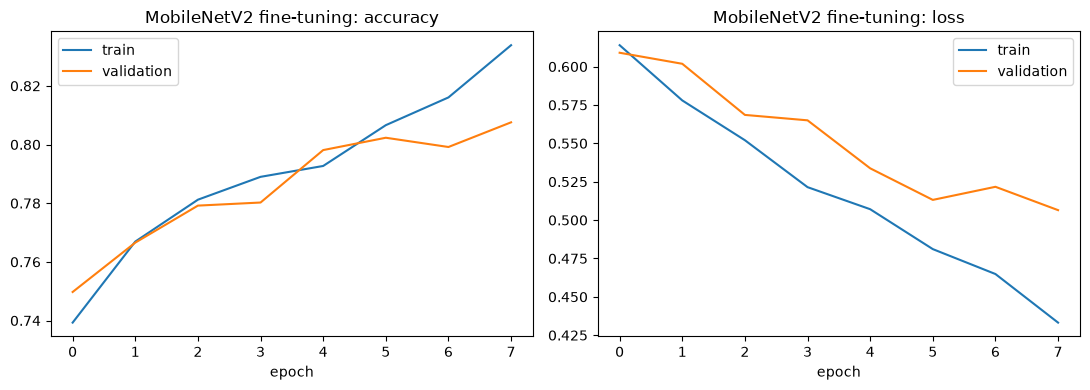

In [8]:
# Stage B: fine-tune the last 30 layers of the base with a small learning rate
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

mobilenet.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss='categorical_crossentropy', metrics=['accuracy'])
hist_b = fit_model(mobilenet, 'fire_mobilenet_stageB', epochs=8)
plot_history(hist_b, 'MobileNetV2 fine-tuning')

MobileNetV2 (fine-tuned): real test accuracy = 78.87%

              precision    recall  f1-score   support

        none       0.76      0.83      0.80       400
       smoke       0.81      0.74      0.77       400
        fire       0.72      0.82      0.77       220
        both       0.85      0.78      0.81       400

    accuracy                           0.79      1420
   macro avg       0.78      0.79      0.79      1420
weighted avg       0.79      0.79      0.79      1420



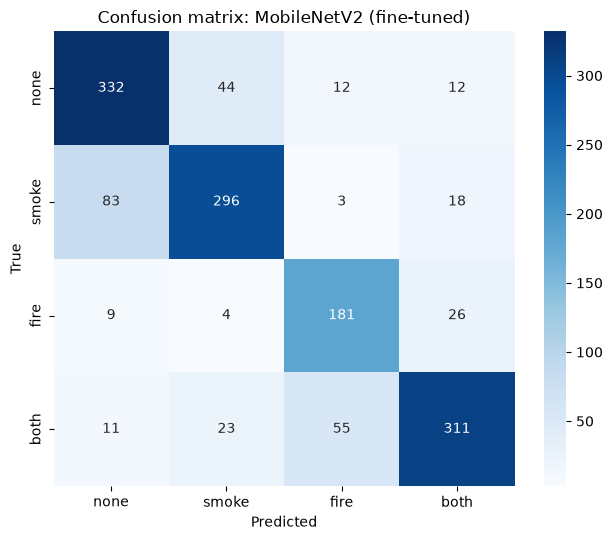

In [9]:
evaluate(mobilenet, 'MobileNetV2 (fine-tuned)', test_gen)

## 6. Compare

                   Model  Real test accuracy (%)
            Baseline CNN                   70.14
MobileNetV2 (fine-tuned)                   78.87


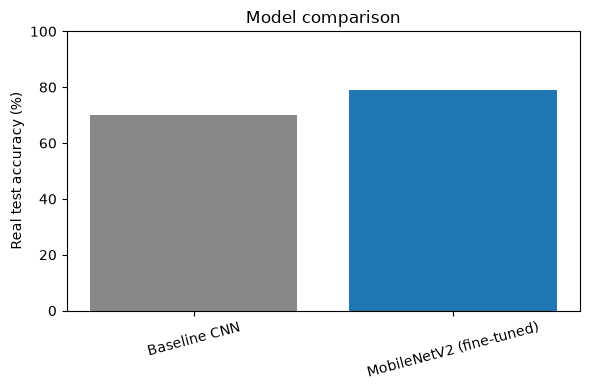

In [10]:
table = pd.DataFrame({'Model': list(results.keys()),
                      'Real test accuracy (%)': [round(v * 100, 2) for v in results.values()]})
print(table.to_string(index=False))

plt.figure(figsize=(6, 4))
plt.bar(table['Model'], table['Real test accuracy (%)'], color=['#888', '#1f77b4', '#2ca02c'][:len(table)])
plt.ylim(0, 100); plt.ylabel('Real test accuracy (%)'); plt.title('Model comparison')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

## 7. Which images does the improved model get wrong?

300 wrong out of 1420


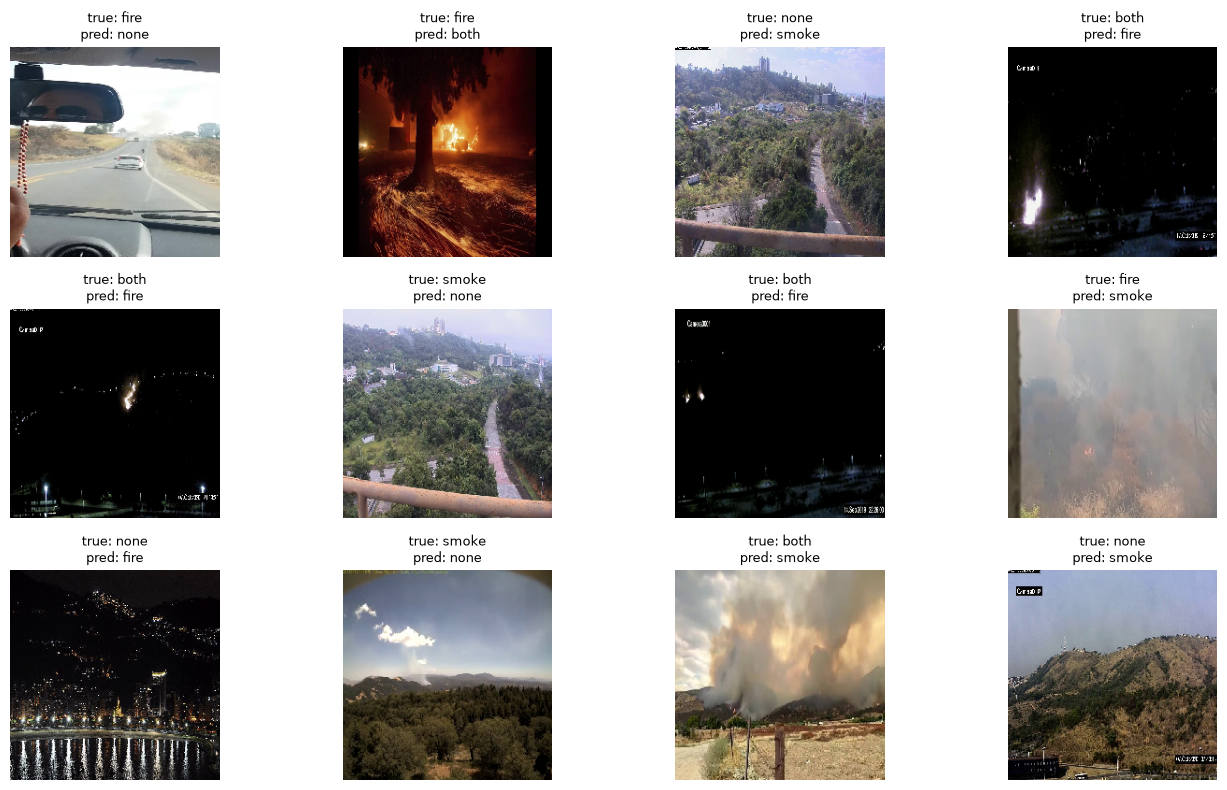

In [11]:
name = 'MobileNetV2 (fine-tuned)'
y_pred = predictions[name]
y_true = test_gen.classes
wrong = np.where(y_pred != y_true)[0]
print(f'{len(wrong)} wrong out of {len(y_true)}')

plt.figure(figsize=(14, 8))
for i, idx in enumerate(np.random.RandomState(0).permutation(wrong)[:12]):
    plt.subplot(3, 4, i + 1)
    plt.imshow(tf.keras.utils.load_img(test_gen.filepaths[idx], target_size=IMG_SIZE))
    plt.axis('off')
    plt.title(f'true: {CLASSES[y_true[idx]]}\npred: {CLASSES[y_pred[idx]]}', fontsize=9)
plt.tight_layout(); plt.show()

## 8. Predict on a single image

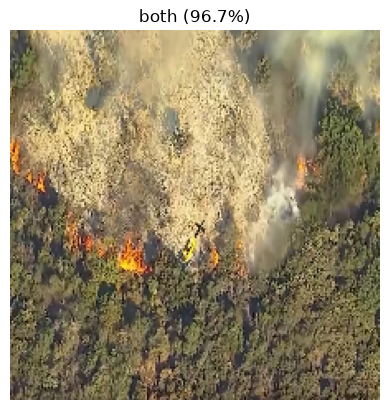

both      96.7%
smoke      2.9%
fire       0.3%
none       0.1%


In [12]:
def predict_image(path, model):
    img = tf.keras.utils.load_img(path, target_size=IMG_SIZE)
    arr = tf.keras.utils.img_to_array(img) / 255.0
    probs = model.predict(arr[None], verbose=0)[0]
    top = np.argsort(probs)[::-1]
    plt.imshow(img); plt.axis('off')
    plt.title(f'{CLASSES[top[0]]} ({probs[top[0]] * 100:.1f}%)')
    plt.show()
    for i in top:
        print(f'{CLASSES[i]:<8}{probs[i] * 100:6.1f}%')

# a random test image; replace with the path of your own photo if you like
sample = test_gen.filepaths[np.random.randint(len(test_gen.filepaths))]
predict_image(sample, mobilenet)